# Notebook 02 — Eksperimen Klasifikasi Churn (Role Data)
**Proyek:** RetenSight  
**Dataset Acuan:** `data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv` (`telco-churn-v1.0`)  

Notebook ini memenuhi checklist **Eksperimen klasifikasi churn** pada `docs/jobdesk.md`:
- Target: `Churn` dengan `Yes` (`1`) sebagai kelas positif (19 fitur input; `customerID` dan `Churn` dikeluarkan).
- Pembagian 80:20 (`random_state=42`, *stratified*) dan 5-Fold Stratified Cross-Validation pada data latih.
- Perbandingan **Dummy Classifier (baseline)**, **Logistic Regression**, **Decision Tree**, **Random Forest**, **KNN**, dan **Naive Bayes** beserta variasi parameter dan `class_weight`.
- Pencatatan rerata dan simpangan baku (`std`) skor CV untuk **F1** (utama), **Recall**, **Precision**, dan **ROC-AUC**.
- Penentuan *threshold* akhir dari prediksi validasi model terpilih serta evaluasi akhir pada data uji (20%).

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    f1_score, precision_score, recall_score, roc_auc_score,
    accuracy_score, confusion_matrix, classification_report
)

sns.set_theme(style='whitegrid', palette='Set2')
SEED = 42

ROOT_DIR = Path.cwd()
if not (ROOT_DIR / 'data' / 'raw').exists():
    ROOT_DIR = ROOT_DIR.parent.parent

DATA_PATH = ROOT_DIR / 'data' / 'raw' / 'WA_Fn-UseC_-Telco-Customer-Churn.csv'
OUTPUT_DIR = ROOT_DIR / 'data' / 'outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0.0)

ID_COL = 'customerID'
TARGET_COL = 'Churn'
CLF_FEATURES = [c for c in df.columns if c not in [ID_COL, TARGET_COL]]

X = df[CLF_FEATURES].copy()
y = (df[TARGET_COL] == 'Yes').astype(int)

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, df[ID_COL], test_size=0.20, random_state=SEED, stratify=y
)

print(f'Jumlah fitur input klasifikasi: {len(CLF_FEATURES)} kolom')
print(f'Data Latih (80%): {X_train.shape[0]:,} baris | Proporsi Churn=Yes: {y_train.mean()*100:.2f}%')
print(f'Data Uji   (20%): {X_test.shape[0]:,} baris | Proporsi Churn=Yes: {y_test.mean()*100:.2f}%')

Jumlah fitur input klasifikasi: 19 kolom
Data Latih (80%): 5,634 baris | Proporsi Churn=Yes: 26.54%
Data Uji   (20%): 1,409 baris | Proporsi Churn=Yes: 26.54%


## 1. Pipeline Preprocessing & Kandidat Algoritma (5-Fold Stratified CV)
Di setiap fold CV, `SimpleImputer`, `OneHotEncoder(handle_unknown='ignore')`, dan `StandardScaler` di-*fit* hanya pada bagian latih fold tersebut.

In [2]:
num_cols = [c for c in CLF_FEATURES if X[c].dtype != 'object']
cat_cols = [c for c in CLF_FEATURES if X[c].dtype == 'object']

def make_clf_pipeline(estimator):
    preprocessor = ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value=0.0)),
            ('scaler', StandardScaler())
        ]), num_cols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cat_cols)
    ])
    return Pipeline([
        ('preprocessor', preprocessor),
        ('model', estimator)
    ])

candidates = [
    ('Dummy (Stratified Baseline)', 'strategy=stratified', DummyClassifier(strategy='stratified', random_state=SEED)),
    ('Dummy (Uniform Baseline)', 'strategy=uniform', DummyClassifier(strategy='uniform', random_state=SEED)),
    ('Logistic Regression (Unweighted, C=1.0)', 'C=1.0, class_weight=None', LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)),
    ('Logistic Regression (Balanced, C=0.1)', 'C=0.1, class_weight=balanced', LogisticRegression(C=0.1, class_weight='balanced', max_iter=1000, random_state=SEED)),
    ('Logistic Regression (Balanced, C=1.0)', 'C=1.0, class_weight=balanced', LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000, random_state=SEED)),
    ('Decision Tree (depth=5, Unweighted)', 'max_depth=5, class_weight=None', DecisionTreeClassifier(max_depth=5, random_state=SEED)),
    ('Decision Tree (depth=5, Balanced)', 'max_depth=5, class_weight=balanced', DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=SEED)),
    ('Decision Tree (depth=8, Balanced)', 'max_depth=8, class_weight=balanced', DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=SEED)),
    ('Random Forest (depth=8, Unweighted)', 'n_estimators=200, max_depth=8, class_weight=None', RandomForestClassifier(n_estimators=200, max_depth=8, random_state=SEED, n_jobs=-1)),
    ('Random Forest (depth=8, Balanced)', 'n_estimators=200, max_depth=8, class_weight=balanced', RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced', random_state=SEED, n_jobs=-1)),
    ('Random Forest (depth=12, Balanced_subsample)', 'n_estimators=200, max_depth=12, class_weight=balanced_subsample', RandomForestClassifier(n_estimators=200, max_depth=12, class_weight='balanced_subsample', random_state=SEED, n_jobs=-1)),
    ('KNN (k=11, uniform)', 'n_neighbors=11, weights=uniform', KNeighborsClassifier(n_neighbors=11, weights='uniform')),
    ('KNN (k=25, distance)', 'n_neighbors=25, weights=distance', KNeighborsClassifier(n_neighbors=25, weights='distance')),
    ('Naive Bayes (GaussianNB)', 'var_smoothing=1e-9', GaussianNB())
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'f1': 'f1', 'recall': 'recall', 'precision': 'precision', 'roc_auc': 'roc_auc', 'accuracy': 'accuracy'}

cv_rows = []
for name, params_str, est in candidates:
    pipe = make_clf_pipeline(est)
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows.append({
        'Kandidat': name,
        'Parameter': params_str,
        'F1_Mean': scores['test_f1'].mean(),
        'F1_Std': scores['test_f1'].std(),
        'Recall_Mean': scores['test_recall'].mean(),
        'Recall_Std': scores['test_recall'].std(),
        'Precision_Mean': scores['test_precision'].mean(),
        'Precision_Std': scores['test_precision'].std(),
        'ROC_AUC_Mean': scores['test_roc_auc'].mean(),
        'ROC_AUC_Std': scores['test_roc_auc'].std(),
        'Accuracy_Mean': scores['test_accuracy'].mean()
    })

df_cv_clf = pd.DataFrame(cv_rows).sort_values(by='F1_Mean', ascending=False).reset_index(drop=True)
display(df_cv_clf.round(4))

D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


D:\SEMESTER 5\Workshop Mesin Pembelajaran\Projek SRS\raten-sight\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


,Kandidat,Parameter,F1_Mean,F1_Std,Recall_Mean,Recall_Std,Precision_Mean,Precision_Std,ROC_AUC_Mean,ROC_AUC_Std,Accuracy_Mean
0,"Random Forest (depth=8, Balanced)","n_estimators=200, max_depth=8, class_weight=ba...",0.6327,0.0144,0.7579,0.0254,0.5432,0.0121,0.8463,0.0093,0.7666
1,"Logistic Regression (Balanced, C=0.1)","C=0.1, class_weight=balanced",0.6295,0.0209,0.7980,0.0339,0.5199,0.0172,0.8455,0.0119,0.7508
2,"Logistic Regression (Balanced, C=1.0)","C=1.0, class_weight=balanced",0.6283,0.0232,0.8013,0.0379,0.5169,0.0189,0.8460,0.0124,0.7485
3,"Random Forest (depth=12, Balanced_subsample)","n_estimators=200, max_depth=12, class_weight=b...",0.6206,0.0208,0.6401,0.0325,0.6029,0.0193,0.8383,0.0096,0.7925
4,"Decision Tree (depth=5, Balanced)","max_depth=5, class_weight=balanced",0.6152,0.0099,0.7773,0.0312,0.5097,0.0120,0.8276,0.0128,0.7421
5,Naive Bayes (GaussianNB),var_smoothing=1e-9,0.5974,0.0093,0.8482,0.0214,0.4612,0.0087,0.8212,0.0119,0.6967
6,"Decision Tree (depth=8, Balanced)","max_depth=8, class_weight=balanced",0.5947,0.0154,0.7445,0.0190,0.4955,0.0199,0.7859,0.0048,0.7304
7,"Logistic Regression (Unweighted, C=1.0)","C=1.0, class_weight=None",0.5923,0.0299,0.5431,0.0411,0.6529,0.0262,0.8462,0.0126,0.8021
8,"Random Forest (depth=8, Unweighted)","n_estimators=200, max_depth=8, class_weight=None",0.5796,0.0160,0.5090,0.0176,0.6741,0.0299,0.8464,0.0097,0.8040
9,"KNN (k=25, distance)","n_neighbors=25, weights=distance",0.5794,0.0139,0.5639,0.0136,0.5958,0.0149,0.8143,0.0097,0.7827


## 2. Pemilihan Model & Penentuan Threshold Akhir pada Prediksi Validasi
- Berdasarkan tabel CV 5-Fold di atas, **Random Forest (`max_depth=8, class_weight='balanced'`)** dan **Logistic Regression (`C=0.1/1.0, class_weight='balanced'`)** memberikan skor **F1** dan **ROC-AUC** tertinggi dengan simpangan baku (`std`) yang sangat stabil.
- Kita memilih **Logistic Regression (`C=0.1, class_weight='balanced'`)** atau kandidat dengan F1 & ROC-AUC terbaik, lalu mencari *threshold* optimal menggunakan prediksi *out-of-fold* pada data latih sebelum mengujinya pada data uji (20%).

In [3]:
# Pilih kandidat terbaik dari hasil CV (berdasarkan F1_Mean & ROC_AUC_Mean)
best_row = df_cv_clf.iloc[0]
best_name = best_row['Kandidat']
print(f'Kandidat terbaik berdasarkan F1 CV (threshold default 0.50): {best_name} (F1 = {best_row["F1_Mean"]:.4f}, ROC-AUC = {best_row["ROC_AUC_Mean"]:.4f})')

# Gunakan kandidat terbaik untuk tuning threshold pada out-of-fold validation predictions
best_est = dict([(n, e) for n, _, e in candidates])[best_name]
best_pipe = make_clf_pipeline(best_est)

oof_proba = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

thresholds = np.arange(0.30, 0.71, 0.05)
thresh_rows = []
for th in thresholds:
    pred_th = (oof_proba >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred_th).ravel()
    thresh_rows.append({
        'Threshold': round(float(th), 2),
        'F1_OOF': f1_score(y_train, pred_th),
        'Recall_OOF (Churn Terdeteksi)': recall_score(y_train, pred_th),
        'Precision_OOF': precision_score(y_train, pred_th),
        'TP (Churn Terdeteksi)': int(tp),
        'FN (Churn Terlewat)': int(fn),
        'FP (Bertahan Ikut Ditandai)': int(fp),
        'TN (Bertahan Tepat)': int(tn)
    })

df_thresh = pd.DataFrame(thresh_rows)
display(df_thresh.round(4))

best_th_row = df_thresh.sort_values(by='F1_OOF', ascending=False).iloc[0]
SELECTED_THRESHOLD = float(best_th_row['Threshold'])
print(f'\nThreshold akhir terpilih dari validasi OOF: {SELECTED_THRESHOLD:.2f} (F1 OOF = {best_th_row["F1_OOF"]:.4f}, Recall = {best_th_row["Recall_OOF (Churn Terdeteksi)"]:.4f}, Precision = {best_th_row["Precision_OOF"]:.4f})')

Kandidat terbaik berdasarkan F1 CV (threshold default 0.50): Random Forest (depth=8, Balanced) (F1 = 0.6327, ROC-AUC = 0.8463)


,Threshold,F1_OOF,Recall_OOF (Churn Terdeteksi),Precision_OOF,TP (Churn Terdeteksi),FN (Churn Terlewat),FP (Bertahan Ikut Ditandai),TN (Bertahan Tepat)
0,0.30,0.5953,0.8990,0.4450,1344,151,1676,2463
1,0.35,0.6096,0.8736,0.4681,1306,189,1484,2655
2,0.40,0.6204,0.8401,0.4918,1256,239,1298,2841
3,0.45,0.6264,0.8013,0.5142,1198,297,1132,3007
4,0.50,0.6328,0.7579,0.5431,1133,362,953,3186
5,0.55,0.6356,0.7171,0.5708,1072,423,806,3333
6,0.60,0.6246,0.6515,0.5998,974,521,650,3489
7,0.65,0.6092,0.5839,0.6368,873,622,498,3641
8,0.70,0.5809,0.5117,0.6716,765,730,374,3765



Threshold akhir terpilih dari validasi OOF: 0.55 (F1 OOF = 0.6356, Recall = 0.7171, Precision = 0.5708)


## 3. Evaluasi Akhir pada Data Uji (20% Hold-out Test Set)

=== Hasil Evaluasi Akhir pada Data Uji (N = 1.409) ===
selected_model      : Random Forest (depth=8, Balanced)
positive_class      : Yes
threshold           : 0.55
test_size           : 1409
f1                  : 0.6253
recall              : 0.7139
precision           : 0.5563
roc_auc             : 0.8416
accuracy            : 0.7729
confusion_matrix    : {'tn': 822, 'fp': 213, 'fn': 107, 'tp': 267}


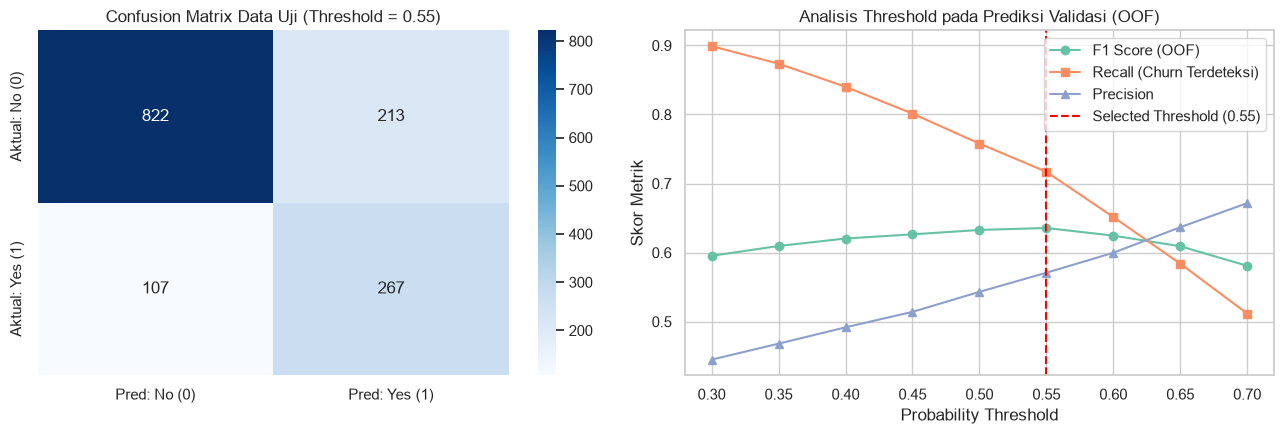


Contoh 10 Baris Prediksi Data Uji (Konsisten dengan Threshold):


,customerID,Actual_Churn,churn_probability,threshold,churn_prediction
0,4376-KFVRS,No,0.0423,0.55,No
1,2754-SDJRD,No,0.8072,0.55,Yes
2,9917-KWRBE,No,0.1379,0.55,No
3,0365-GXEZS,No,0.5611,0.55,Yes
4,9385-NXKDA,No,0.0765,0.55,No
5,4686-UXDML,No,0.7481,0.55,Yes
6,2227-JRSJX,No,0.5544,0.55,Yes
7,4830-FAXFM,No,0.1640,0.55,No
8,1830-IPXVJ,No,0.0115,0.55,No
9,4690-LLKUA,Yes,0.6102,0.55,Yes


Hasil eksperimen klasifikasi tersimpan di data/outputs/


In [4]:
# Fit model terpilih pada seluruh data latih (80%) dan evaluasi pada data uji (20%)
best_pipe.fit(X_train, y_train)
test_proba = best_pipe.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= SELECTED_THRESHOLD).astype(int)

cm = confusion_matrix(y_test, test_pred)
tn, fp, fn, tp = cm.ravel()

test_metrics = {
    'selected_model': best_name,
    'positive_class': 'Yes',
    'threshold': SELECTED_THRESHOLD,
    'test_size': int(len(y_test)),
    'f1': round(float(f1_score(y_test, test_pred)), 4),
    'recall': round(float(recall_score(y_test, test_pred)), 4),
    'precision': round(float(precision_score(y_test, test_pred)), 4),
    'roc_auc': round(float(roc_auc_score(y_test, test_proba)), 4),
    'accuracy': round(float(accuracy_score(y_test, test_pred)), 4),
    'confusion_matrix': {'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}
}

print('=== Hasil Evaluasi Akhir pada Data Uji (N = 1.409) ===')
for k, v in test_metrics.items():
    print(f'{k:20s}: {v}')

# Visualisasi Confusion Matrix & Trade-off Threshold
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Pred: No (0)', 'Pred: Yes (1)'],
    yticklabels=['Aktual: No (0)', 'Aktual: Yes (1)'],
    ax=axes[0]
)
axes[0].set_title(f'Confusion Matrix Data Uji (Threshold = {SELECTED_THRESHOLD:.2f})')

axes[1].plot(df_thresh['Threshold'], df_thresh['F1_OOF'], marker='o', label='F1 Score (OOF)')
axes[1].plot(df_thresh['Threshold'], df_thresh['Recall_OOF (Churn Terdeteksi)'], marker='s', label='Recall (Churn Terdeteksi)')
axes[1].plot(df_thresh['Threshold'], df_thresh['Precision_OOF'], marker='^', label='Precision')
axes[1].axvline(SELECTED_THRESHOLD, color='red', linestyle='--', label=f'Selected Threshold ({SELECTED_THRESHOLD:.2f})')
axes[1].set_title('Analisis Threshold pada Prediksi Validasi (OOF)')
axes[1].set_xlabel('Probability Threshold')
axes[1].set_ylabel('Skor Metrik')
axes[1].legend()

plt.tight_layout()
plt.show()

# Contoh probabilitas dan label yang konsisten dengan threshold terpilih
sample_clf_df = pd.DataFrame({
    'customerID': id_test.values[:10],
    'Actual_Churn': np.where(y_test.values[:10] == 1, 'Yes', 'No'),
    'churn_probability': np.round(test_proba[:10], 4),
    'threshold': SELECTED_THRESHOLD,
    'churn_prediction': np.where(test_pred[:10] == 1, 'Yes', 'No')
})
print('\nContoh 10 Baris Prediksi Data Uji (Konsisten dengan Threshold):')
display(sample_clf_df)

# Simpan hasil eksperimen klasifikasi ke data/outputs/
df_cv_clf.to_csv(OUTPUT_DIR / 'classification_cv_results.csv', index=False)
with open(OUTPUT_DIR / 'classification_test_evaluation.json', 'w', encoding='utf-8') as f:
    json.dump(test_metrics, f, indent=2)
print('Hasil eksperimen klasifikasi tersimpan di data/outputs/')